In [1]:
import numpy as nu
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Limpieza y pre-analisis

Cargar cvs

In [2]:
df = pd.read_csv('data/train.csv')
df.head(5)

,id,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,268,1002,Dell,Inspiron 5567,Notebook,15.6,1366x768,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00
1,347,867,Asus,X541NA (N4200/4GB/1TB/W10),Notebook,15.6,1366x768,Intel Pentium Quad Core N4200 1.1GHz,4GB,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00
2,353,966,Toshiba,Portege Z30-C-1CW,Notebook,13.3,Full HD 1920x1080,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00
3,578,767,Dell,Alienware 17,Gaming,15.6,IPS Panel 4K Ultra HD 3840x2160,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99
4,42,1241,Dell,Latitude E7270,Ultrabook,12.5,Full HD / Touchscreen 1920x1080,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 912 entries, 0 to 911
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                912 non-null    int64  
 1   laptop_ID         912 non-null    int64  
 2   Company           912 non-null    object 
 3   Product           912 non-null    object 
 4   TypeName          912 non-null    object 
 5   Inches            912 non-null    float64
 6   ScreenResolution  912 non-null    object 
 7   Cpu               912 non-null    object 
 8   Ram               912 non-null    object 
 9   Memory            912 non-null    object 
 10  Gpu               912 non-null    object 
 11  OpSys             912 non-null    object 
 12  Weight            912 non-null    object 
 13  Price_euros       912 non-null    float64
dtypes: float64(2), int64(2), object(10)
memory usage: 99.9+ KB


In [4]:
df.describe()

,id,laptop_ID,Inches,Price_euros
count,912.000000,912.000000,912.000000,912.000000
mean,645.091009,666.192982,15.011404,1108.122873
std,380.313813,384.873846,1.411744,714.597741
min,0.000000,1.000000,10.100000,174.000000
25%,319.750000,330.500000,14.000000,589.000000
50%,636.500000,673.500000,15.600000,949.000000
75%,980.250000,998.500000,15.600000,1458.500000
max,1302.000000,1320.000000,18.400000,6099.000000


## Outliers de precio

In [5]:
Q1 = df['Price_euros'].quantile(0.25)
Q3 = df['Price_euros'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Price_euros'] < lower) | (df['Price_euros'] > upper)]

print(f"Q1:     {Q1:.2f}€")
print(f"Q3:     {Q3:.2f}€")
print(f"IQR:    {IQR:.2f}€")
print(f"Límite inferior: {lower:.2f}€")
print(f"Límite superior: {upper:.2f}€")
print(f"Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

Q1:     589.00€
Q3:     1458.50€
IQR:    869.50€
Límite inferior: -715.25€
Límite superior: 2762.75€
Outliers: 29 (3.2%)


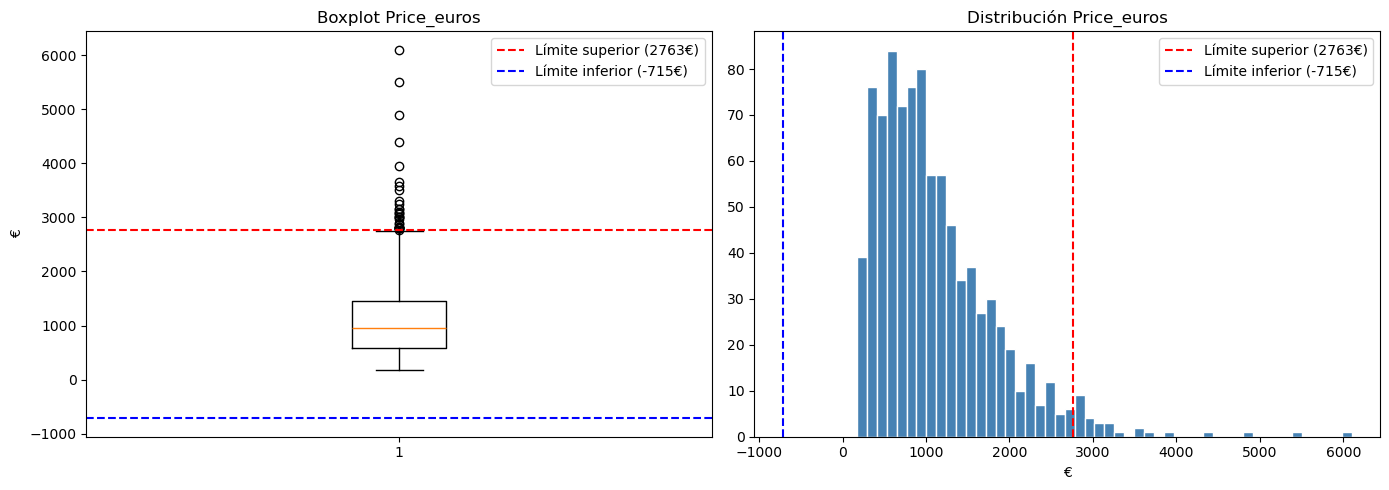

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
axes[0].boxplot(df['Price_euros'], vert=True)
axes[0].axhline(upper, color='red', linestyle='--', label=f'Límite superior ({upper:.0f}€)')
axes[0].axhline(lower, color='blue', linestyle='--', label=f'Límite inferior ({lower:.0f}€)')
axes[0].set_title('Boxplot Price_euros')
axes[0].set_ylabel('€')
axes[0].legend()

# Histograma
axes[1].hist(df['Price_euros'], bins=50, color='steelblue', edgecolor='white')
axes[1].axvline(upper, color='red', linestyle='--', label=f'Límite superior ({upper:.0f}€)')
axes[1].axvline(lower, color='blue', linestyle='--', label=f'Límite inferior ({lower:.0f}€)')
axes[1].set_title('Distribución Price_euros')
axes[1].set_xlabel('€')
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
outliers[['id', 'Company', 'Product', 'TypeName', 'Price_euros']].sort_values('Price_euros', ascending=False)

,id,Company,Product,TypeName,Price_euros
73,909,Razer,Blade Pro,Gaming,6099.00
837,73,Razer,Blade Pro,Gaming,5499.00
18,518,Lenovo,Thinkpad P51,Notebook,4899.00
789,202,HP,Zbook 17,Workstation,4389.00
567,1170,HP,ZBook 17,Workstation,3949.40
173,813,Dell,Alienware 17,Gaming,3659.40
368,333,Dell,Alienware 17,Gaming,3588.80
206,1167,Razer,Blade Pro,Gaming,3499.00
905,1052,Lenovo,Thinkpad P51s,Workstation,3299.00
880,46,Lenovo,IdeaPad Y900-17ISK,Gaming,3240.00


## Laptop_ID - eliminar, no aporta

In [8]:
df = df.drop(columns='laptop_ID')

## Company

In [9]:
df.value_counts('Company')

Company
Lenovo       208
Dell         207
HP           189
Asus         108
Acer          75
Toshiba       37
MSI           34
Apple         17
Mediacom       7
Samsung        6
Razer          6
Microsoft      3
Vero           3
Xiaomi         3
Fujitsu        3
Google         2
Chuwi          2
Huawei         1
LG             1
Name: count, dtype: int64

In [10]:
df.groupby('Company')['Price_euros'].mean().sort_values(ascending=True).reset_index()

,Company,Price_euros
0,Vero,224.566667
1,Chuwi,246.945000
2,Mediacom,295.000000
3,Acer,644.774800
4,Fujitsu,729.000000
5,Asus,1034.531852
6,HP,1042.357884
7,Xiaomi,1044.633333
8,Lenovo,1099.752548
9,Dell,1175.476570


In [11]:
company_order = df.groupby('Company')['Price_euros'].mean().sort_values(ascending=True).reset_index()
company_order['company_encod'] = range(len(company_order))
df = df.merge(company_order[['Company', 'company_encod']], on='Company')
df = df.drop(columns='Company')


## Product - eliminar, no aporta

In [12]:
df = df.drop(columns='Product')

## TypeName

In [13]:
df['TypeName'].value_counts()

TypeName
Notebook              522
Gaming                138
Ultrabook             135
2 in 1 Convertible     85
Workstation            18
Netbook                14
Name: count, dtype: int64

In [14]:
type_order = df.groupby('TypeName')['Price_euros'].mean().sort_values(ascending=True).reset_index()
type_order

,TypeName,Price_euros
0,Netbook,577.992857
1,Notebook,768.970575
2,2 in 1 Convertible,1248.470471
3,Ultrabook,1530.688148
4,Gaming,1764.080217
5,Workstation,2494.864444


In [15]:
type_order['type_encod'] = range(len(type_order))
df = df.merge(type_order[['TypeName', 'type_encod']], on='TypeName')
df = df.drop(columns='TypeName')


## ScreenResolution

In [16]:
df['ScreenResolution'].value_counts().reset_index()

,ScreenResolution,count
0,Full HD 1920x1080,346
1,1366x768,208
2,IPS Panel Full HD 1920x1080,163
3,IPS Panel Full HD / Touchscreen 1920x1080,37
4,Full HD / Touchscreen 1920x1080,32
5,Touchscreen 1366x768,15
6,1600x900,11
7,IPS Panel 4K Ultra HD 3840x2160,10
8,4K Ultra HD / Touchscreen 3840x2160,8
9,Quad HD+ / Touchscreen 3200x1800,8


In [17]:
df['ScreenResolution'] = df['ScreenResolution'].str.replace(r'\d+x\d+', '', regex=True).str.strip()


In [18]:
df

,id,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod
0,268,15.6,,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1
1,347,15.6,,Intel Pentium Quad Core N4200 1.1GHz,4GB,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1
2,353,13.3,Full HD,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1
3,578,15.6,IPS Panel 4K Ultra HD,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4
4,42,12.5,Full HD / Touchscreen,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3
...,...,...,...,...,...,...,...,...,...,...,...,...
907,89,11.6,IPS Panel Touchscreen,Intel Celeron Dual Core N3060 1.6GHz,4GB,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2
908,716,13.3,Full HD,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1
909,517,15.6,,AMD A8-Series 7410 2.2GHz,8GB,1TB HDD,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1
910,891,14.0,Full HD,Intel Core i7 7600U 2.8GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3


In [19]:
df['ScreenResolution'].value_counts().reset_index()

,ScreenResolution,count
0,Full HD,346
1,,226
2,IPS Panel Full HD,165
3,IPS Panel Full HD / Touchscreen,37
4,Full HD / Touchscreen,32
5,Touchscreen,24
6,IPS Panel Retina Display,14
7,IPS Panel 4K Ultra HD,10
8,IPS Panel Touchscreen,9
9,Quad HD+ / Touchscreen,8


In [20]:
df['Touchscreen'] = df['ScreenResolution'].str.contains('Touchscreen').astype(int)
df['ScreenResolution'] = df['ScreenResolution'].str.replace('/ Touchscreen', '', regex=False).str.replace('Touchscreen', '', regex=False).str.strip()


In [21]:
df

,id,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod,Touchscreen
0,268,15.6,,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1,0
1,347,15.6,,Intel Pentium Quad Core N4200 1.1GHz,4GB,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1,0
2,353,13.3,Full HD,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1,0
3,578,15.6,IPS Panel 4K Ultra HD,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4,0
4,42,12.5,Full HD,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
907,89,11.6,IPS Panel,Intel Celeron Dual Core N3060 1.6GHz,4GB,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2,1
908,716,13.3,Full HD,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1,0
909,517,15.6,,AMD A8-Series 7410 2.2GHz,8GB,1TB HDD,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1,0
910,891,14.0,Full HD,Intel Core i7 7600U 2.8GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3,0


In [22]:
df['ScreenResolution'].value_counts()

ScreenResolution
Full HD                     378
                            250
IPS Panel Full HD           202
IPS Panel 4K Ultra HD        18
IPS Panel                    17
IPS Panel Retina Display     14
4K Ultra HD                  13
Quad HD+                     10
IPS Panel Quad HD+            6
IPS Panel  / 4K Ultra HD      2
/ Full HD                     1
/ 4K Ultra HD                 1
Name: count, dtype: int64

In [23]:
df['IPS_Panel'] = df['ScreenResolution'].str.contains('IPS Panel').astype(int)
df['ScreenResolution'] = df['ScreenResolution'].str.replace('IPS Panel', '', regex=False).str.strip()
df['ScreenResolution'] = df['ScreenResolution'].str.replace(r'\s*/\s*', ' ', regex=True).str.strip()

In [24]:
df

,id,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod,Touchscreen,IPS_Panel
0,268,15.6,,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1,0,0
1,347,15.6,,Intel Pentium Quad Core N4200 1.1GHz,4GB,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1,0,0
2,353,13.3,Full HD,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1,0,0
3,578,15.6,4K Ultra HD,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4,0,1
4,42,12.5,Full HD,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
907,89,11.6,,Intel Celeron Dual Core N3060 1.6GHz,4GB,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2,1,1
908,716,13.3,Full HD,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1,0,0
909,517,15.6,,AMD A8-Series 7410 2.2GHz,8GB,1TB HDD,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1,0,0
910,891,14.0,Full HD,Intel Core i7 7600U 2.8GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3,0,0


In [25]:
df['ScreenResolution'].value_counts()

ScreenResolution
Full HD           581
                  267
4K Ultra HD        34
Quad HD+           16
Retina Display     14
Name: count, dtype: int64

In [26]:
screen_order = df.groupby('ScreenResolution')['Price_euros'].mean().sort_values(ascending=True).reset_index()
screen_order

,ScreenResolution,Price_euros
0,,650.718614
1,Full HD,1208.758141
2,Quad HD+,1507.483750
3,Retina Display,1675.537857
4,4K Ultra HD,2558.836471


In [27]:
screen_order['screen_encod'] = range(len(screen_order))
df = df.merge(screen_order[['ScreenResolution', 'screen_encod']], on='ScreenResolution')
df = df.drop(columns='ScreenResolution')


In [28]:
df

,id,Inches,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod,Touchscreen,IPS_Panel,screen_encod
0,268,15.6,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1,0,0,0
1,347,15.6,Intel Pentium Quad Core N4200 1.1GHz,4GB,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1,0,0,0
2,353,13.3,Intel Core i5 6200U 2.3GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1,0,0,1
3,578,15.6,Intel Core i7 7700HQ 2.8GHz,16GB,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4,0,1,4
4,42,12.5,Intel Core i5 6300U 2.4GHz,8GB,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
907,89,11.6,Intel Celeron Dual Core N3060 1.6GHz,4GB,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2,1,1,0
908,716,13.3,Intel Core i5 6200U 2.3GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1,0,0,1
909,517,15.6,AMD A8-Series 7410 2.2GHz,8GB,1TB HDD,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1,0,0,0
910,891,14.0,Intel Core i7 7600U 2.8GHz,8GB,256GB SSD,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3,0,0,1


## CPU

In [29]:
df['Cpu'].value_counts()

Cpu
Intel Core i5 7200U 2.5GHz     142
Intel Core i7 7700HQ 2.8GHz    102
Intel Core i7 7500U 2.7GHz      88
Intel Core i5 8250U 1.6GHz      54
Intel Core i5 6200U 2.3GHz      51
                              ... 
Intel Core i7 7660U 2.5GHz       1
AMD E-Series E2-9000 2.2GHz      1
Intel Core i3 6006U 2.2GHz       1
Intel Core i7 2.8GHz             1
AMD E-Series 9000 2.2GHz         1
Name: count, Length: 104, dtype: int64

In [30]:
# ghz_cpu: número decimal antes de "GHz"
df['ghz_cpu'] = df['Cpu'].str.extract(r'(\d+\.?\d*)GHz', expand=False).astype(float)

# tipo_cpu: marca + familia del procesador (sin modelo ni frecuencia)
df['tipo_cpu'] = df['Cpu'].str.extract(
    r'^(Intel Core i\d+|Intel Pentium|Intel Celeron|Intel Atom|Intel Xeon|'
    r'AMD [A-Z]\d+-Series|AMD E-Series|AMD FX|AMD Ryzen \d+|AMD A-Series)',
    expand=False
)

df[['Cpu', 'tipo_cpu', 'ghz_cpu']].head(10)


,Cpu,tipo_cpu,ghz_cpu
0,Intel Core i7 7500U 2.7GHz,Intel Core i7,2.7
1,Intel Pentium Quad Core N4200 1.1GHz,Intel Pentium,1.1
2,Intel Core i5 6200U 2.3GHz,Intel Core i5,2.3
3,Intel Core i7 7700HQ 2.8GHz,Intel Core i7,2.8
4,Intel Core i5 6300U 2.4GHz,Intel Core i5,2.4
5,Intel Core i7 7500U 2.7GHz,Intel Core i7,2.7
6,Intel Core i3 6006U 2GHz,Intel Core i3,2.0
7,Intel Core i7 7700HQ 2.8GHz,Intel Core i7,2.8
8,Intel Core i7 7500U 2.7GHz,Intel Core i7,2.7
9,Intel Core i7 7700HQ 2.8GHz,Intel Core i7,2.8


In [31]:
df['tipo_cpu'].value_counts()

tipo_cpu
Intel Core i7     351
Intel Core i5     305
Intel Core i3      99
Intel Celeron      62
Intel Pentium      26
Intel Atom         12
AMD A9-Series      11
AMD E-Series        7
AMD A12-Series      6
AMD A6-Series       6
Intel Xeon          4
AMD A10-Series      3
AMD FX              2
AMD A8-Series       2
AMD Ryzen 1700      2
AMD Ryzen 1600      1
Name: count, dtype: int64

In [32]:
df['ghz_cpu'] = df['Cpu'].str.extract(r'(\d+\.?\d*)GHz', expand=False).astype(float)

df['tipo_cpu'] = df['Cpu'].str.extract(
    r'^(Intel Core i\d+|Intel Pentium|Intel Celeron|Intel Atom|Intel Xeon|'
    r'AMD [A-Z]\d+-Series|AMD E-Series|AMD FX|AMD Ryzen \d+|AMD A-Series)',
    expand=False
)

cpu_order = df.groupby('tipo_cpu')['Price_euros'].mean().sort_values(ascending=True).reset_index()
cpu_order['cpu_encod'] = range(len(cpu_order))
df = df.merge(cpu_order[['tipo_cpu', 'cpu_encod']], on='tipo_cpu')

ghz_order = df.groupby('ghz_cpu')['Price_euros'].mean().sort_values(ascending=True).reset_index()
ghz_order['ghz_encod'] = range(len(ghz_order))
df = df.merge(ghz_order[['ghz_cpu', 'ghz_encod']], on='ghz_cpu')

df = df.drop(columns=['Cpu', 'tipo_cpu'])
cpu_order


,tipo_cpu,Price_euros,cpu_encod
0,AMD E-Series,300.141429,0
1,Intel Celeron,312.009194,1
2,Intel Atom,324.821667,2
3,AMD A6-Series,398.815000,3
4,AMD A8-Series,418.000000,4
5,Intel Pentium,439.373462,5
6,AMD A9-Series,471.542727,6
7,Intel Core i3,539.186768,7
8,AMD A10-Series,599.636667,8
9,AMD A12-Series,605.428333,9


## RAM

In [33]:
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)
df

,id,Inches,Ram,Memory,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod,Touchscreen,IPS_Panel,screen_encod,ghz_cpu,cpu_encod,ghz_encod
0,268,15.6,8,1TB HDD,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1,0,0,0,2.7,13,15
1,347,15.6,4,1TB HDD,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1,0,0,0,1.1,5,3
2,353,13.3,8,256GB SSD,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1,0,0,1,2.3,11,12
3,578,15.6,16,256GB SSD + 1TB HDD,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4,0,1,4,2.8,13,20
4,42,12.5,8,256GB SSD,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3,1,0,1,2.4,11,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,89,11.6,4,32GB Flash Storage,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2,1,1,0,1.6,1,6
895,716,13.3,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1,0,0,1,2.3,11,12
896,517,15.6,8,1TB HDD,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1,0,0,0,2.2,4,9
897,891,14.0,8,256GB SSD,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3,0,0,1,2.8,13,20


## Sistema operativo

In [34]:
df['OpSys'].value_counts()

OpSys
Windows 10      741
Linux            47
No OS            44
Windows 7        32
Chrome OS        18
macOS            10
Windows 10 S      3
Mac OS X          2
Android           2
Name: count, dtype: int64

## Memoria

In [35]:
import re

def extract_gb(memory_str, storage_type):
    pattern = rf'(\d+(?:\.\d+)?)(GB|TB)\s+{re.escape(storage_type)}'
    match = re.search(pattern, str(memory_str), re.IGNORECASE)
    if match:
        value = float(match.group(1))
        return value * 1024 if match.group(2).upper() == 'TB' else value
    return 0

df['memory_ssd']   = df['Memory'].apply(lambda x: extract_gb(x, 'SSD'))
df['memory_hdd']   = df['Memory'].apply(lambda x: extract_gb(x, 'HDD'))
df['memory_flash'] = df['Memory'].apply(lambda x: extract_gb(x, 'Flash Storage'))

df = df.drop(columns='Memory')
df


,id,Inches,Ram,Gpu,OpSys,Weight,Price_euros,company_encod,type_encod,Touchscreen,IPS_Panel,screen_encod,ghz_cpu,cpu_encod,ghz_encod,memory_ssd,memory_hdd,memory_flash
0,268,15.6,8,AMD Radeon R7 M445,Windows 10,2.36kg,749.00,9,1,0,0,0,2.7,13,15,0.0,1024.0,0.0
1,347,15.6,4,Intel HD Graphics 505,Windows 10,2kg,449.00,5,1,0,0,0,1.1,5,3,0.0,1024.0,0.0
2,353,13.3,8,Intel HD Graphics 520,Windows 7,1.2kg,1460.00,10,1,0,0,1,2.3,11,12,256.0,0.0,0.0
3,578,15.6,16,Nvidia GeForce GTX 1070,Windows 10,4.42kg,2868.99,9,4,0,1,4,2.8,13,20,256.0,1024.0,0.0
4,42,12.5,8,Intel HD Graphics 520,Windows 7,1.26kg,1713.37,9,3,1,0,1,2.4,11,8,256.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,89,11.6,4,Intel HD Graphics 400,Chrome OS,1.25kg,389.00,3,2,1,1,0,1.6,1,6,0.0,0.0,32.0
895,716,13.3,4,Intel HD Graphics 520,Windows 10,1.2kg,1195.00,10,1,0,0,1,2.3,11,12,128.0,0.0,0.0
896,517,15.6,8,AMD Radeon R5,Windows 10,2.4kg,449.00,3,1,0,0,0,2.2,4,9,0.0,1024.0,0.0
897,891,14.0,8,Intel HD Graphics 620,Windows 10,1.36kg,1775.00,9,3,0,0,1,2.8,13,20,256.0,0.0,0.0


## GPU

In [36]:
gpu_df = df['Gpu'].value_counts()
gpu_df.head(50)

Gpu
Intel HD Graphics 620             199
Intel HD Graphics 520             138
Intel UHD Graphics 620             45
Nvidia GeForce GTX 1050            43
Nvidia GeForce GTX 1060            31
Intel HD Graphics 400              28
AMD Radeon 530                     27
Intel HD Graphics 500              27
Nvidia GeForce 940MX               26
Nvidia GeForce GTX 1070            24
Intel HD Graphics                  23
Nvidia GeForce GTX 1050 Ti         21
AMD Radeon R5 M430                 18
Nvidia GeForce 930MX               16
Nvidia GeForce MX150               12
Nvidia GeForce 920MX               11
AMD Radeon 520                     11
Intel HD Graphics 505              11
Nvidia GeForce GTX 960M            10
Intel HD Graphics 615               9
AMD Radeon R7 M445                  9
AMD Radeon R5                       8
Nvidia Quadro M1200                 7
Intel HD Graphics 405               7
Intel Iris Plus Graphics 640        6
Nvidia GeForce 930M                 5
AMD Rade

In [37]:
gpu_order = df.groupby('Gpu')['Price_euros'].mean().sort_values(ascending=True).reset_index()
gpu_order['gpu_encod'] = range(len(gpu_order))
df = df.merge(gpu_order[['Gpu', 'gpu_encod']], on='Gpu')

gpu_order.head(50)


,Gpu,Price_euros,gpu_encod
0,AMD Radeon R2,268.996667,0
1,Intel HD Graphics 400,316.245357,1
2,AMD Radeon R2 Graphics,323.500000,2
3,Intel HD Graphics 500,326.735926,3
4,AMD Radeon R4 Graphics,339.000000,4
5,AMD Radeon R4,398.000000,5
6,AMD R4 Graphics,399.000000,6
7,Intel HD Graphics 405,401.998571,7
8,Intel HD Graphics,405.390435,8
9,AMD Radeon R5,425.748750,9


Se elimina la columna por no ser categorizada

In [38]:
df = df.drop(columns='Gpu')

In [39]:
opsys_order = df.groupby('OpSys')['Price_euros'].mean().sort_values(ascending=True).reset_index()
opsys_order['opsys_encod'] = range(len(opsys_order))
df = df.merge(opsys_order[['OpSys', 'opsys_encod']], on='OpSys')
df = df.drop(columns='OpSys')

opsys_order


,OpSys,Price_euros,opsys_encod
0,Android,434.000000,0
1,Chrome OS,526.827778,1
2,No OS,539.476136,2
3,Linux,622.786809,3
4,Windows 10,1147.433036,4
5,Windows 10 S,1161.946667,5
6,Mac OS X,1549.485000,6
7,macOS,1720.580000,7
8,Windows 7,1765.166875,8


## Peso - weight

In [40]:
df['Weight'] = df['Weight'].str.replace('kg', '').astype(float)

df

,id,Inches,Ram,Weight,Price_euros,company_encod,type_encod,Touchscreen,IPS_Panel,screen_encod,ghz_cpu,cpu_encod,ghz_encod,memory_ssd,memory_hdd,memory_flash,gpu_encod,opsys_encod
0,268,15.6,8,2.36,749.00,9,1,0,0,0,2.7,13,15,0.0,1024.0,0.0,33,4
1,347,15.6,4,2.00,449.00,5,1,0,0,0,1.1,5,3,0.0,1024.0,0.0,12,4
2,353,13.3,8,1.20,1460.00,10,1,0,0,1,2.3,11,12,256.0,0.0,0.0,40,8
3,578,15.6,16,4.42,2868.99,9,4,0,1,4,2.8,13,20,256.0,1024.0,0.0,79,4
4,42,12.5,8,1.26,1713.37,9,3,1,0,1,2.4,11,8,256.0,0.0,0.0,40,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894,89,11.6,4,1.25,389.00,3,2,1,1,0,1.6,1,6,0.0,0.0,32.0,1,1
895,716,13.3,4,1.20,1195.00,10,1,0,0,1,2.3,11,12,128.0,0.0,0.0,40,4
896,517,15.6,8,2.40,449.00,3,1,0,0,0,2.2,4,9,0.0,1024.0,0.0,9,4
897,891,14.0,8,1.36,1775.00,9,3,0,0,1,2.8,13,20,256.0,0.0,0.0,46,4


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 899 entries, 0 to 898
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             899 non-null    int64  
 1   Inches         899 non-null    float64
 2   Ram            899 non-null    int64  
 3   Weight         899 non-null    float64
 4   Price_euros    899 non-null    float64
 5   company_encod  899 non-null    int64  
 6   type_encod     899 non-null    int64  
 7   Touchscreen    899 non-null    int64  
 8   IPS_Panel      899 non-null    int64  
 9   screen_encod   899 non-null    int64  
 10  ghz_cpu        899 non-null    float64
 11  cpu_encod      899 non-null    int64  
 12  ghz_encod      899 non-null    int64  
 13  memory_ssd     899 non-null    float64
 14  memory_hdd     899 non-null    float64
 15  memory_flash   899 non-null    float64
 16  gpu_encod      899 non-null    int64  
 17  opsys_encod    899 non-null    int64  
dtypes: float64

In [42]:
df.to_csv('data/train_trans.csv', index=False)

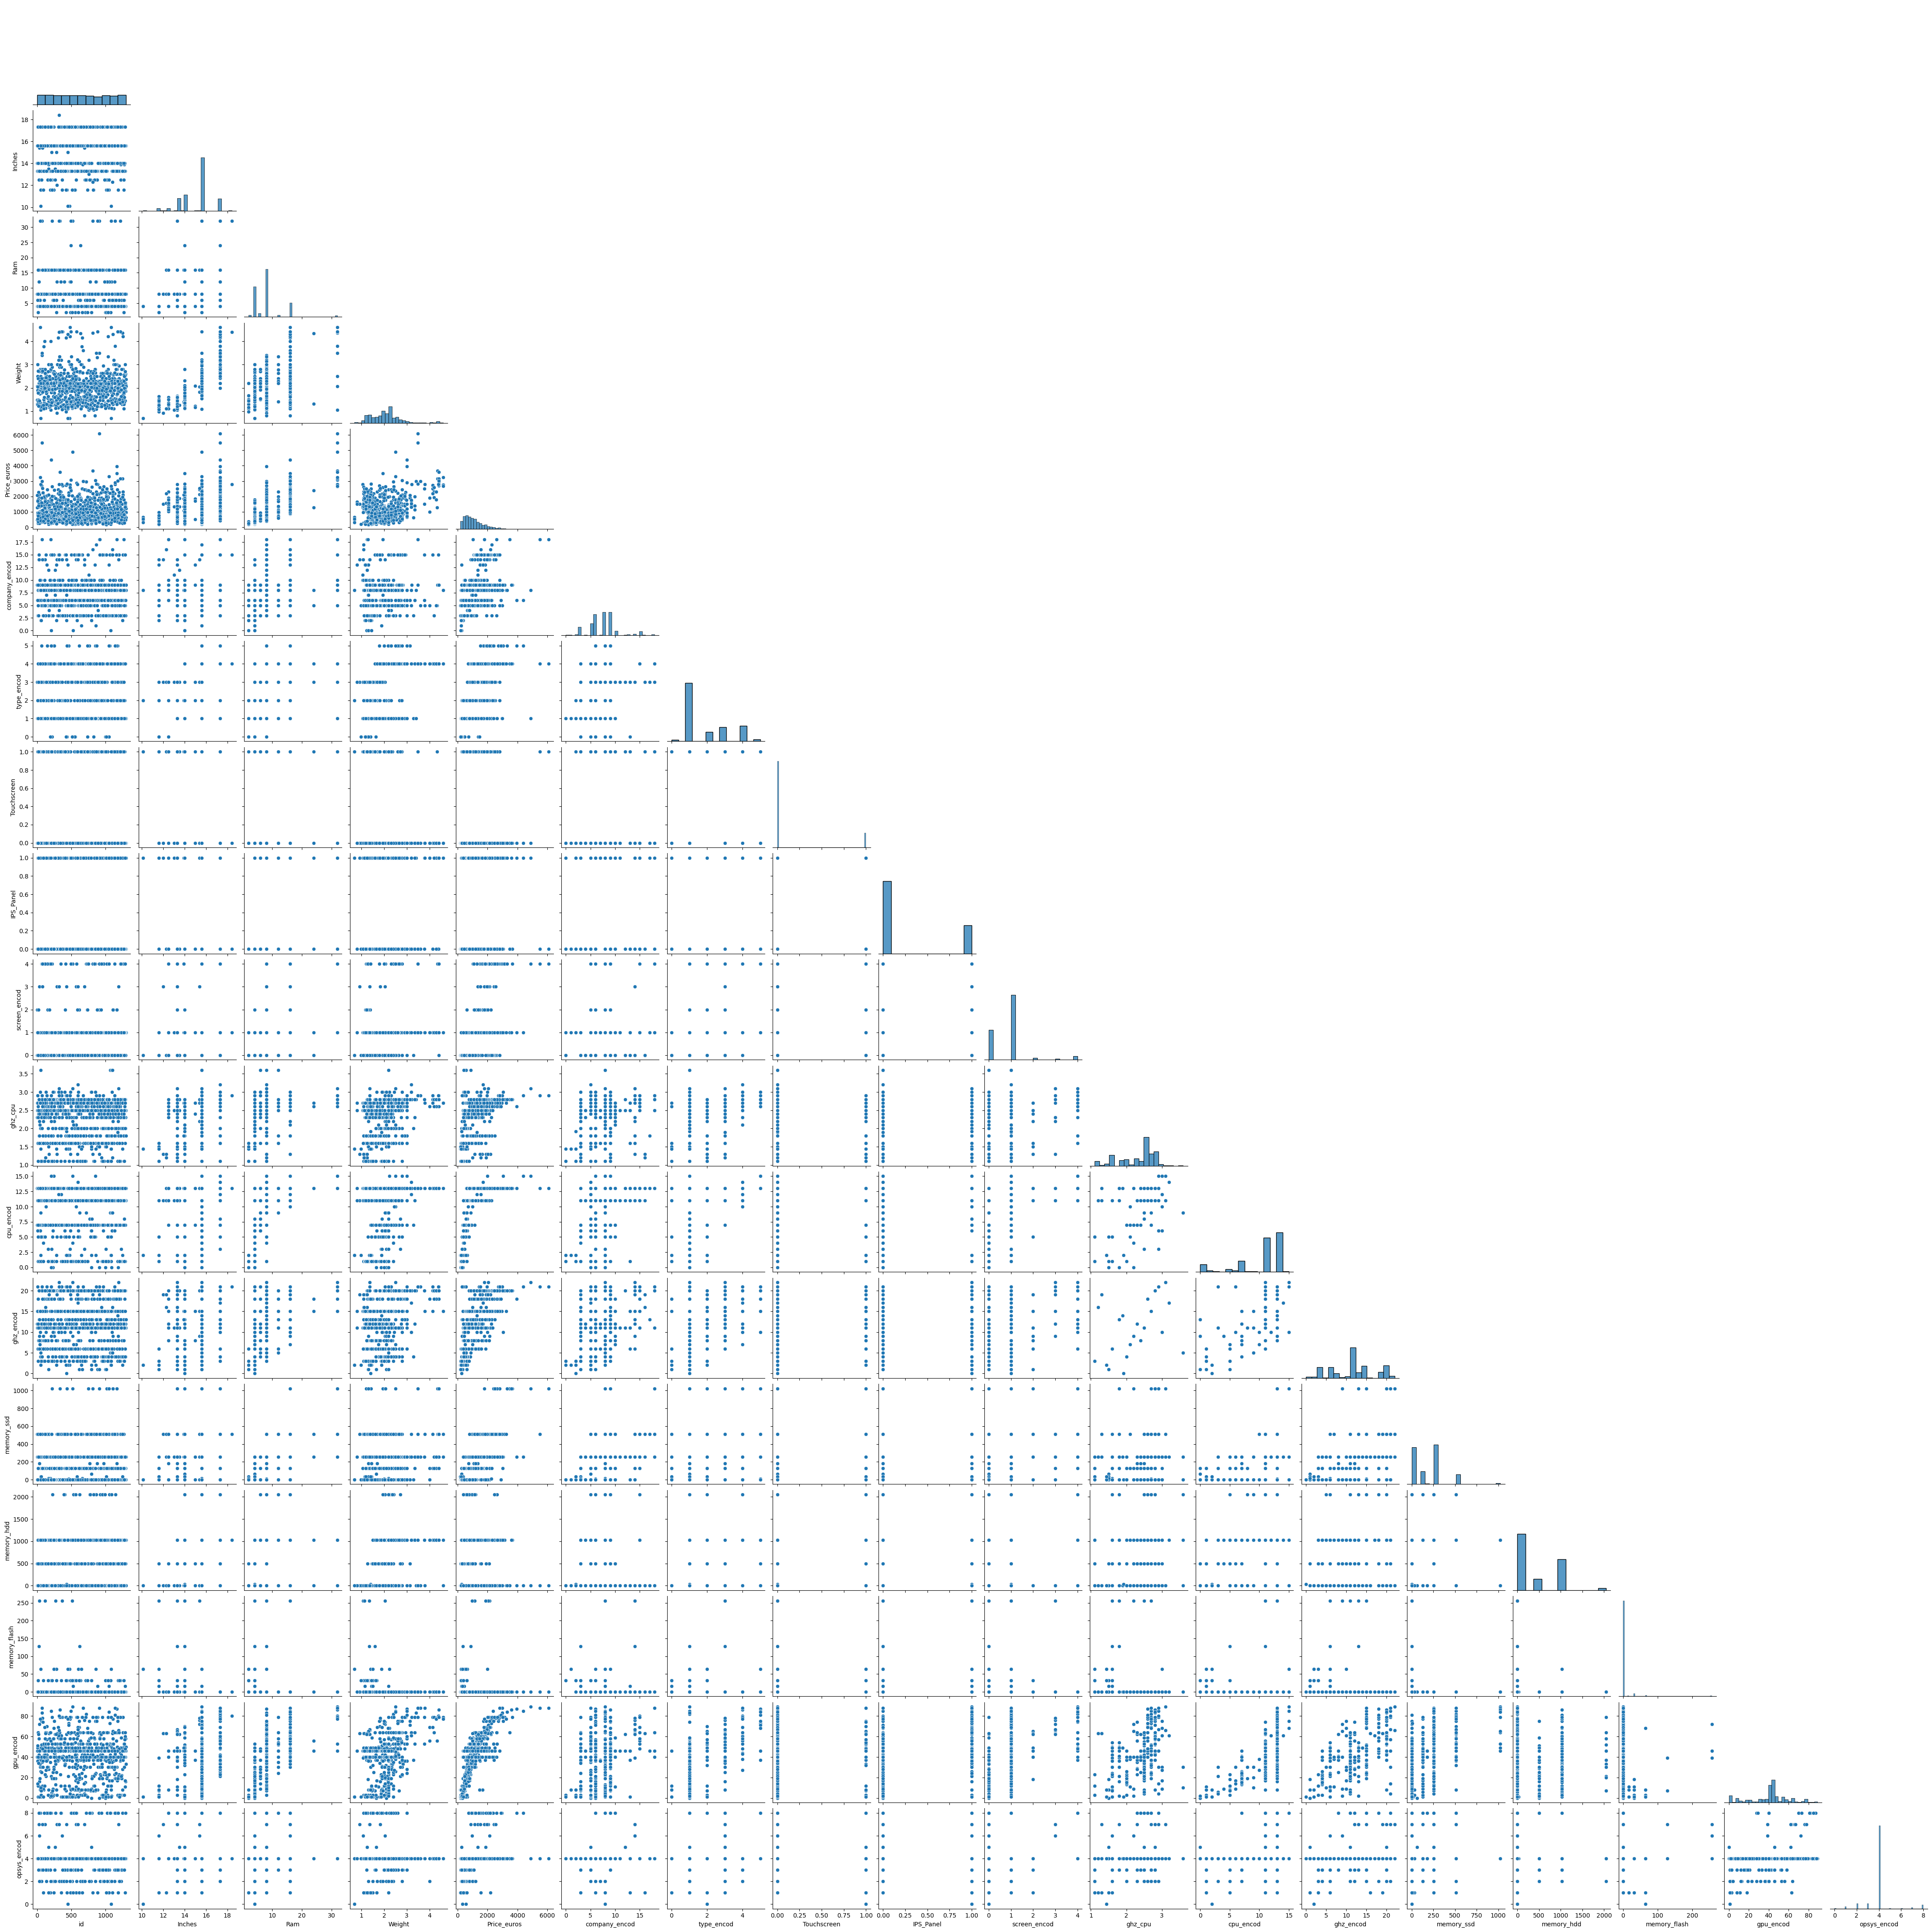

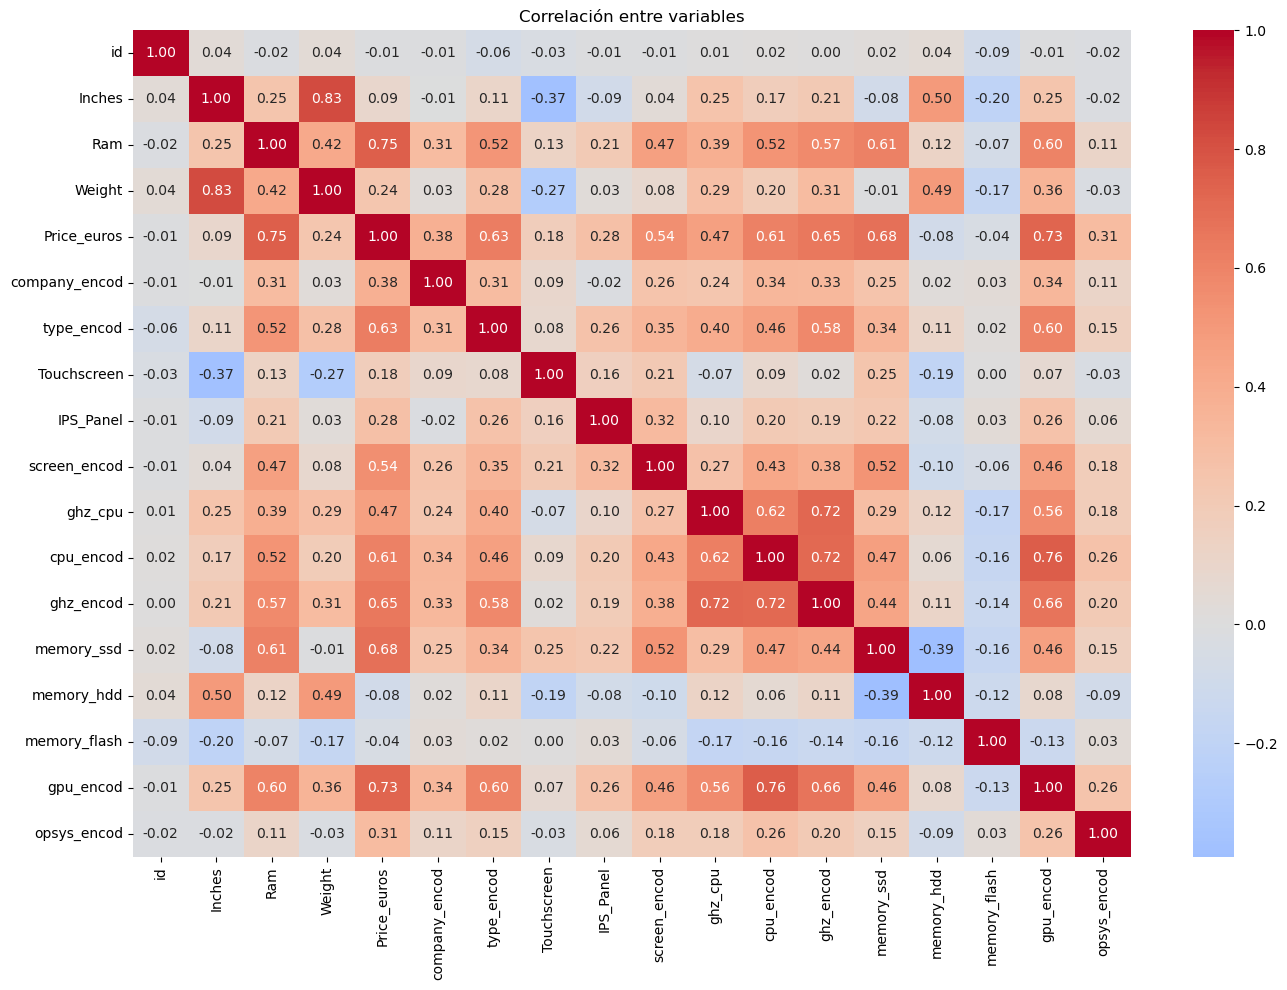

In [43]:
# Pairplot
sns.pairplot(df, corner=True)
plt.show()

# Heatmap de correlaciones
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlación entre variables')
plt.tight_layout()
plt.show()
